# Normalizing flows: from change of variables to learned densities — exercises

Skoltech · Bayesian machine learning

The Laplace approximation represents a posterior by one Gaussian. MCMC instead
constructs a sequence of dependent draws from a target distribution. A normalizing
flow learns a distribution by transforming independent draws from a simple base.
The transformation also gives a tractable, normalized density.

We first derive change of variables, then implement an affine transformation,
an affine coupling layer, and a RealNVP model. A supplied training loop fits a
two-dimensional density to noisy moons. Task 4 fits a full-resolution MNIST
image model on a GPU, with image grids and latent-space visualizations.
Appendix A uses the same model as a
variational approximation to a curved, posterior-shaped target and compares it
with Laplace. Appendix B studies masks and support.

The prerequisites are multivariate densities, the chain rule, Jacobians, and
basic PyTorch: modules, tensors, automatic differentiation, and gradient descent.
There are four implementation tasks. Tasks 1–3 form the 90-minute core;
Task 4 is a GPU practical extension. The appendices are optional.


## Setup

Use Python 3.9+ with NumPy, Matplotlib, PyTorch, torchvision, IPython, and a
notebook interface. Install `requirements.txt` using a matching PyTorch and
torchvision build for your CUDA environment. Tasks 1–3 generate data locally
and run on a CPU. Task 4 downloads MNIST on its first run and uses a CUDA GPU.
Run cells in order.

Each task has a function contract, checks, an experiment, and interpretation
questions. Checks skip an implementation that raises `NotImplementedError`.
After completing a task, rerun its checks and the dependent experiments. Other
errors are allowed to fail so that incorrect implementations are visible.

`RUN_MNIST` enables the GPU practical. Without CUDA its training is skipped
with an explicit message; its mathematical checks still run on a CPU.
`RUN_APPENDICES` enables the additional experiments. Fixed seeds make the
examples repeatable on a given software stack; last digits can vary across
versions. Training budgets and model sizes are fixed before test evaluation.


In [ ]:
import copy
import math
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Markdown

RUN_APPENDICES = False
RUN_MNIST = True
TRAIN_STEPS = 1200
VI_STEPS = 1400
DEVICE = torch.device("cpu")
DTYPE = torch.float32
torch.set_num_threads(1)  # Small networks are usually faster with one CPU thread.
torch.manual_seed(2026)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 3.5), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.18})
completed = set()

def table(headers, rows):
    def fmt(value):
        if isinstance(value, (float, np.floating)):
            return f"{value:.5g}"
        return str(value)
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(map(fmt, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

def check_task(label, test):
    completed.discard(label)
    try:
        test()
    except NotImplementedError:
        print(f"Task {label}: unfinished; dependent experiments will be skipped.")
        return False
    completed.add(label)
    print(f"Task {label}: checks passed.")
    return True

def ready(*labels):
    missing = [str(label) for label in labels if label not in completed]
    if missing:
        print("Complete Task " + ", ".join(missing) + " to run this experiment.")
    return not missing

def standard_normal_log_prob(z):
    """Independent N(0,1) coordinates; z:(B,d) -> log density:(B,)."""
    return -0.5 * (z.square() + math.log(2 * math.pi)).sum(dim=-1)

def assert_close(actual, expected, atol=1e-8, rtol=1e-8):
    torch.testing.assert_close(actual, expected, atol=atol, rtol=rtol)

print(f"PyTorch {torch.__version__}; device={DEVICE}; dtype={DTYPE}")


## 1. A distribution defined by a transformation

Let $Z\in\mathbb R^d$ have a known density $p_0$, usually
$\mathcal N(0,I_d)$. Let $g_\phi:\mathbb R^d\to\mathbb R^d$ be a differentiable
bijection with a differentiable inverse and a nonsingular Jacobian. Define
$$X=g_\phi(Z),\qquad f_\phi=g_\phi^{-1}.$$
Here $g$ always denotes the generating direction, from base to data.
The inverse $f$ encodes data into base coordinates. Some libraries use
`forward` for encoding; the name alone does not determine a Jacobian sign.

In one dimension, a small interval of width $dz$ becomes an interval of width
$dx\approx |g_\phi'(z)|dz$. Conservation of probability gives
$$q_\phi(x)\,dx=p_0(z)\,dz,
\qquad q_\phi(x)=\frac{p_0(z)}{|g_\phi'(z)|},\quad z=f_\phi(x).$$
Stretching reduces density height; compression increases it. The absolute
value handles orientation reversal. A density can exceed one: probability is
an integral of density over a region.

In $d$ dimensions, the determinant measures local volume change:
$$q_\phi(x)=p_0(f_\phi(x))\,|\det Df_\phi(x)|.$$
Since $Df_\phi(x)=[Dg_\phi(z)]^{-1}$ at $x=g_\phi(z)$,
$$\boxed{\log q_\phi(x)=\log p_0(z)-\log|\det Dg_\phi(z)|
       =\log p_0(f_\phi(x))+\log|\det Df_\phi(x)|.}$$
The signs differ because the two Jacobians describe opposite maps. Under
these assumptions $q_\phi$ integrates to one for every parameter value;
no partition function needs to be estimated.


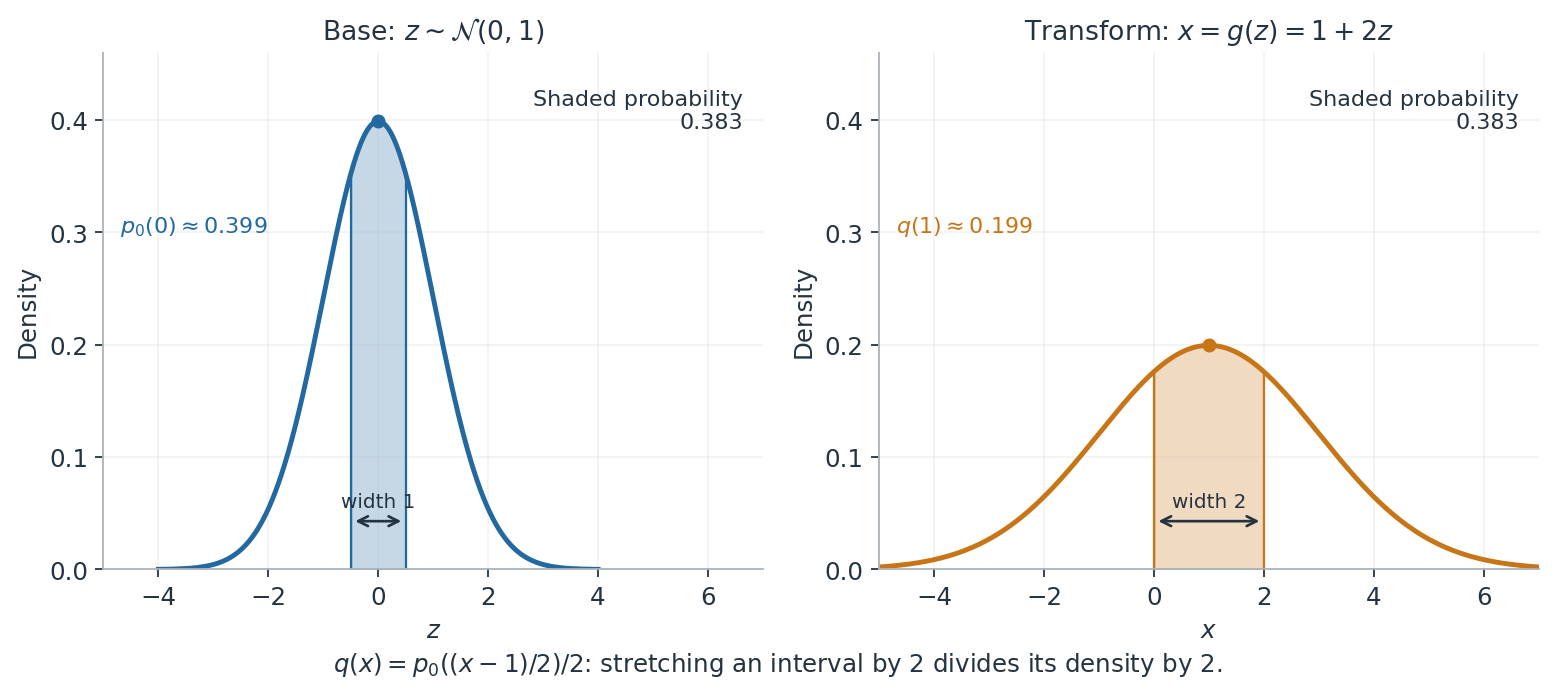

The shaded intervals carry the same probability. Stretching the horizontal axis by a factor of two halves density height and doubles interval width.


## Task 1 — An affine flow in one dimension

Take $Z\sim\mathcal N(0,1)$ and
$$X=g(z)=\mu+e^a z,\qquad f(x)=(x-\mu)e^{-a}.$$
The real parameter $a$ is a log standard deviation, not a variance.
The generating log determinant is $a$ and the inverse log determinant is $-a$.
Thus
$$\log q(x)=-\tfrac12[f(x)^2+\log(2\pi)]-a.$$

1. Implement `affine_1d(value, shift, log_scale, inverse=False)`. Return the
   transformed tensor and the log absolute derivative of the applied map,
   broadcast to the input shape. `inverse=False` applies $g$.
2. Implement `affine_log_prob(x, shift, log_scale)` using the inverse map.
3. Predict the mean and standard deviation for $\mu=1$, $a=\log 2$.
   Explain why adding $a$ when evaluating the density would be incorrect.

Inputs are floating PyTorch tensors; `shift` and `log_scale` are scalars.
Preserve the tensor's dtype, device, and gradients.


In [ ]:
def affine_1d(value, shift, log_scale, inverse=False):
    """Return (transformed, applied_logdet), both with value.shape."""
    shift = torch.as_tensor(shift, dtype=value.dtype, device=value.device)
    log_scale = torch.as_tensor(log_scale, dtype=value.dtype, device=value.device)
    # TODO: apply g or g^{-1}, and return the signed log absolute derivative.
    raise NotImplementedError("Task 1")

def affine_log_prob(x, shift, log_scale):
    """Return the elementwise log density at x, with shape x.shape."""
    # TODO: encode x, evaluate the standard normal, and add inverse logdet.
    raise NotImplementedError("Task 1")


In [ ]:
def test_affine():
    z = torch.tensor([-1.2, 0.0, 0.7], dtype=torch.float64)
    for a in [math.log(2), math.log(0.3)]:
        x, ld = affine_1d(z, 1.0, a)
        recovered, ild = affine_1d(x, 1.0, a, inverse=True)
        assert x.shape == ld.shape == z.shape
        assert x.dtype == z.dtype and x.device == z.device
        assert_close(x, 1 + math.exp(a) * z)
        assert_close(recovered, z)
        assert_close(ld, torch.full_like(z, a))
        assert_close(ld + ild, torch.zeros_like(z))
        reference = torch.distributions.Normal(z.new_tensor(1), z.new_tensor(math.exp(a)))
        assert_close(affine_log_prob(x, 1.0, a), reference.log_prob(x))
    # A density integral, not just a round-trip check, detects sign mistakes.
    grid = torch.linspace(-15, 17, 20001, dtype=torch.float64)
    integral = torch.trapz(affine_log_prob(grid, 1.0, math.log(2)).exp(), grid)
    assert_close(integral, grid.new_tensor(1), atol=1e-7)
    a = torch.tensor(0.3, dtype=torch.float64, requires_grad=True)
    score = affine_log_prob(z, 1.0, a).sum()
    grad, = torch.autograd.grad(score, a)
    expected = (((z - 1) * torch.exp(-a)).square() - 1).sum()
    assert_close(grad, expected)

check_task(1, test_affine)


In [ ]:
if ready(1):
    rng = torch.Generator().manual_seed(11)
    z = torch.randn(12000, generator=rng, dtype=torch.float64)
    x, _ = affine_1d(z, 1.0, math.log(2))
    table(["Quantity", "Sample", "Exact"],
          [["Mean", x.mean().item(), 1.0],
           ["Standard deviation", x.std().item(), 2.0]])
    grid = torch.linspace(-7, 9, 500, dtype=torch.float64)
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.hist(x.numpy(), bins=65, density=True, alpha=0.35, label="Transformed draws")
    ax.plot(grid, affine_log_prob(grid, 1.0, math.log(2)).exp(), label="Flow density")
    ax.set(xlabel="x", ylabel="Density", title="An affine flow is still Gaussian")
    ax.legend(); plt.show()


Your interpretation:

_Write your answer here._


## 2. Why a generic neural network is not enough

A useful flow needs three operations: evaluate the generating map, evaluate its
inverse, and evaluate the log absolute determinant of its Jacobian. A generic
neural network need not be bijective. Even for a bijective network, a numerical
inverse or a dense $d\times d$ determinant can be expensive; a generic dense
determinant costs $O(d^3)$ once its Jacobian is available.

RealNVP [1] uses affine coupling. Split coordinates into preserved part $A$
and transformed part $B$:
$$y_A=u_A,\qquad y_B=u_B\odot\exp s_\phi(u_A)+t_\phi(u_A).$$
The functions $s$ and $t$ can be ordinary neural networks. They do not have to
be invertible because the unchanged $u_A=y_A$ is available in both directions:
$$u_A=y_A,\qquad
u_B=(y_B-t_\phi(y_A))\odot\exp[-s_\phi(y_A)].$$
For this ordering of coordinates, the Jacobian is block triangular:
$$Dg(u)=\begin{pmatrix}I&0\\ *&\operatorname{diag}(e^{s_\phi(u_A)})\end{pmatrix},
\qquad\log|\det Dg(u)|=\sum_{j\in B}s_{\phi,j}(u_A).$$
The $*$ block includes derivatives of both networks, but does not enter the
determinant. The inverse log determinant is the negative of this sum evaluated
at the matching preserved coordinates.

### A mask and a stable scale

Use a binary mask $m\in\{0,1\}^2$ with one preserved coordinate. Feed $m\odot u$
to a network whose four outputs are split into $s_{\rm raw},t_{\rm raw}\in\mathbb R^2$.
Set
$$s=1.5\tanh(s_{\rm raw})\odot(1-m),\qquad
t=t_{\rm raw}\odot(1-m).$$
Then $g(u)=m\odot u+(1-m)\odot(u\odot e^s+t)$. Masking ensures that the networks
depend only on the preserved coordinate. Bounding $s$ controls each layer's
scale, $e^{-1.5}<e^{s_j}<e^{1.5}$, while translations remain unrestricted.
This improves numerical behavior without changing the inverse formula.


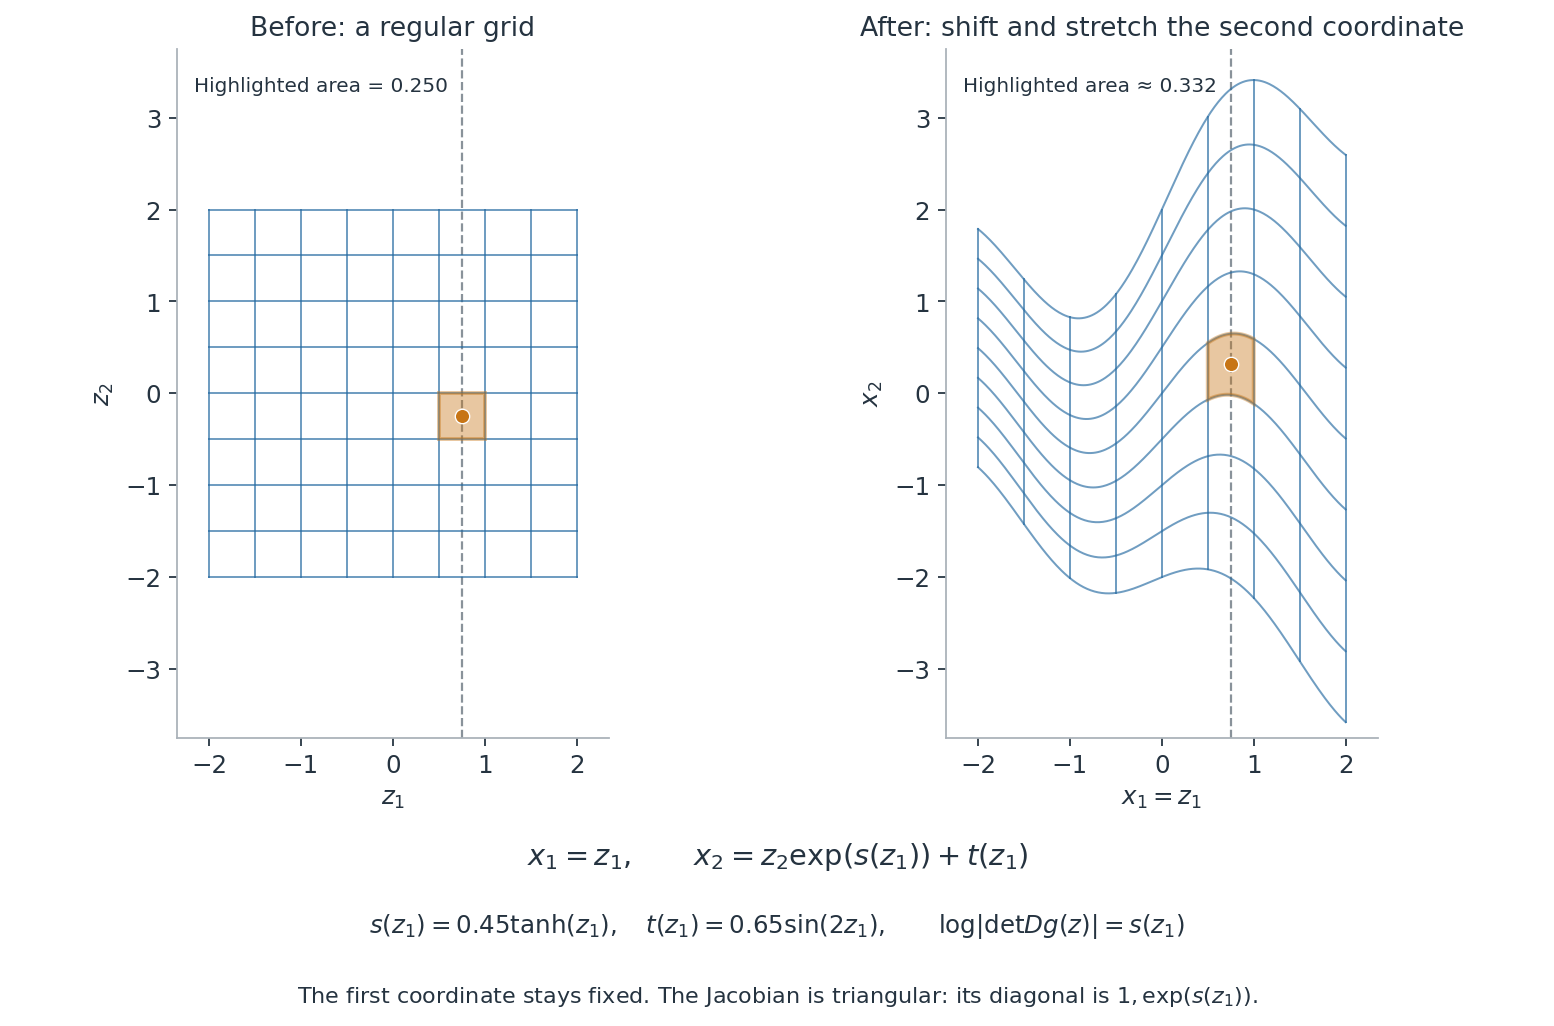

A coupling layer preserves the first coordinate and changes vertical locations and spacing. Its triangular Jacobian makes the local area factor inexpensive to evaluate.


## Task 2 — An affine coupling layer

Complete `AffineCoupling.transform(x, inverse=False)`.

1. Compute $s,t$ from the masked input and apply the generating map or inverse.
2. Return `(output, logdet)` with shapes `(B, 2)` and `(B,)`. The determinant
   must describe the applied map and must include a sum over coordinates.
3. Explain why the inverse reuses the same network instead of inverting it.

The constructor, registered mask, and network are supplied. The last linear
layer starts at zero, so each coupling initially equals the identity. Checks
deliberately use nonzero parameters: testing only the initial identity would
miss most sign and masking errors. Preserve gradients through both outputs.


In [ ]:
class AffineCoupling(nn.Module):
    def __init__(self, mask, hidden=32, scale_limit=1.5):
        super().__init__()
        mask = torch.tensor(mask, dtype=torch.float32)
        if mask.shape != (2,) or not torch.all((mask == 0) | (mask == 1)) or mask.sum() != 1:
            raise ValueError("mask must be [1, 0] or [0, 1]")
        self.register_buffer("mask", mask)
        self.scale_limit = scale_limit
        self.net = nn.Sequential(nn.Linear(2, hidden), nn.Tanh(),
                                 nn.Linear(hidden, hidden), nn.Tanh(),
                                 nn.Linear(hidden, 4))
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def transform(self, x, inverse=False):
        """x:(B,2) -> (output:(B,2), applied_logdet:(B,))."""

        # TODO: masked conditioner, bounded scale, transformation, and logdet.
        raise NotImplementedError("Task 2")


In [ ]:
def test_coupling():
    for mask in ([1, 0], [0, 1]):
        layer = AffineCoupling(mask).double()
        # Replace the conditioner by a known, nonconstant linear map.
        layer.net = nn.Linear(2, 4).double()
        with torch.no_grad():
            layer.net.weight.copy_(torch.tensor([[0.2, -0.1], [-0.3, 0.2],
                                                [0.4, 0.1], [-0.2, 0.3]], dtype=torch.float64))
            layer.net.bias.copy_(torch.tensor([0.2, -0.15, 0.3, -0.2], dtype=torch.float64))
        x = torch.tensor([[-0.7, 0.2], [0.4, 1.1], [1.2, -0.3]], dtype=torch.float64)
        y, ld = layer.transform(x)
        xr, ild = layer.transform(y, inverse=True)
        assert y.shape == x.shape and ld.shape == (len(x),)
        # Known conditioner gives a separate numerical oracle for scale AND shift.
        expected = x.clone()
        if mask == [1, 0]:
            expected_ld = 1.5*torch.tanh(-0.3*x[:, 0] - 0.15)
            expected[:, 1] = x[:, 1]*expected_ld.exp() - 0.2*x[:, 0] - 0.2
        else:
            expected_ld = 1.5*torch.tanh(-0.1*x[:, 1] + 0.2)
            expected[:, 0] = x[:, 0]*expected_ld.exp() + 0.1*x[:, 1] + 0.3
        assert_close(y, expected)
        assert_close(ld, expected_ld)
        assert_close(xr, x)
        assert_close(ld + ild, torch.zeros_like(ld))
        assert_close(y * layer.mask, x * layer.mask)
        assert (y - x).abs().max() > 0.05
        assert "mask" in dict(layer.named_buffers())
        # Compare both signs against a full automatic-differentiation Jacobian.
        for inverse, points in [(False, x), (True, y.detach())]:
            for point in points:
                jac = torch.autograd.functional.jacobian(
                    lambda v: layer.transform(v[None], inverse=inverse)[0][0], point)
                sign, reference = torch.linalg.slogdet(jac)
                _, analytic = layer.transform(point[None], inverse=inverse)
                assert sign > 0
                assert_close(analytic[0], reference)
        loss = y.square().mean() + ld.mean()
        gradients = torch.autograd.grad(loss, tuple(layer.parameters()))
        assert all(torch.isfinite(g).all() for g in gradients)
        assert sum(g.abs().sum().item() for g in gradients) > 0

check_task(2, test_coupling)


In [ ]:
if ready(2):
    # A supplied exact conditioner illustrates a nonlinear, invertible layer.
    class ExampleConditioner(nn.Module):
        def forward(self, x):
            zeros = torch.zeros_like(x[:, :1])
            raw_s2 = torch.atanh(0.3 * torch.tanh(x[:, :1]))
            t2 = 0.65 * torch.sin(2 * x[:, :1])
            return torch.cat([zeros, raw_s2, zeros, t2], dim=-1)

    demo_layer = AffineCoupling([1, 0])
    demo_layer.net = ExampleConditioner()
    rng = torch.Generator().manual_seed(12)
    z = torch.randn(2500, 2, generator=rng)
    with torch.no_grad():
        x, ld = demo_layer.transform(z)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    for ax, values, title in zip(axes, [z, x], ["Base draws", "After one coupling"]):
        ax.scatter(values[:, 0], values[:, 1], c=z[:, 0], cmap="viridis", s=4, alpha=0.5)
        ax.set(xlabel="Coordinate 1", ylabel="Coordinate 2", title=title,
               xlim=(-3, 3), ylim=(-4, 4))
    plt.tight_layout(); plt.show()
    table(["Quantity", "Value"], [["Max change in preserved coordinate", (x[:, 0]-z[:, 0]).abs().max().item()],
                                ["Minimum log determinant", ld.min().item()],
                                ["Maximum log determinant", ld.max().item()]])


Interpretation questions. Which marginal distribution is unchanged by this
layer? If every layer preserves coordinate 1, can the resulting flow fit an
arbitrary distribution for that coordinate? Why does a full Jacobian check
provide information that a round-trip check alone does not?


Your interpretation:

_Write your answer here._


## 3. Composition, density evaluation, and sampling

Compose $K$ generating layers:
$$h_0=z,\quad h_k=g_k(h_{k-1}),\quad x=h_K=g_\phi(z).$$
By the chain rule and multiplicativity of determinants,
$$\log|\det Dg_\phi(z)|=\sum_{k=1}^K\log|\det Dg_k(h_{k-1})|.$$
To encode $x$, apply $g_K^{-1},g_{K-1}^{-1},\ldots,g_1^{-1}$ in that order.
Each layer returns the log determinant of its applied map, so the same sum
accumulates the correct inverse sign without another manual sign change.

For an input batch of shape `(B, 2)`, transformed coordinates have shape
`(B, 2)`, while base log probabilities and accumulated determinants have
shape `(B,)`. The standard normal log density sums over coordinates:
$$\log p_0(z)=-\tfrac12\sum_{j=1}^2[z_j^2+\log(2\pi)].$$
The mean over observations belongs in the training loss, after the per-example
log probability has been computed.

We use six affine couplings with alternating masks. This is a small 2D RealNVP
model [1]; it omits the image-specific multiscale architecture of that paper.


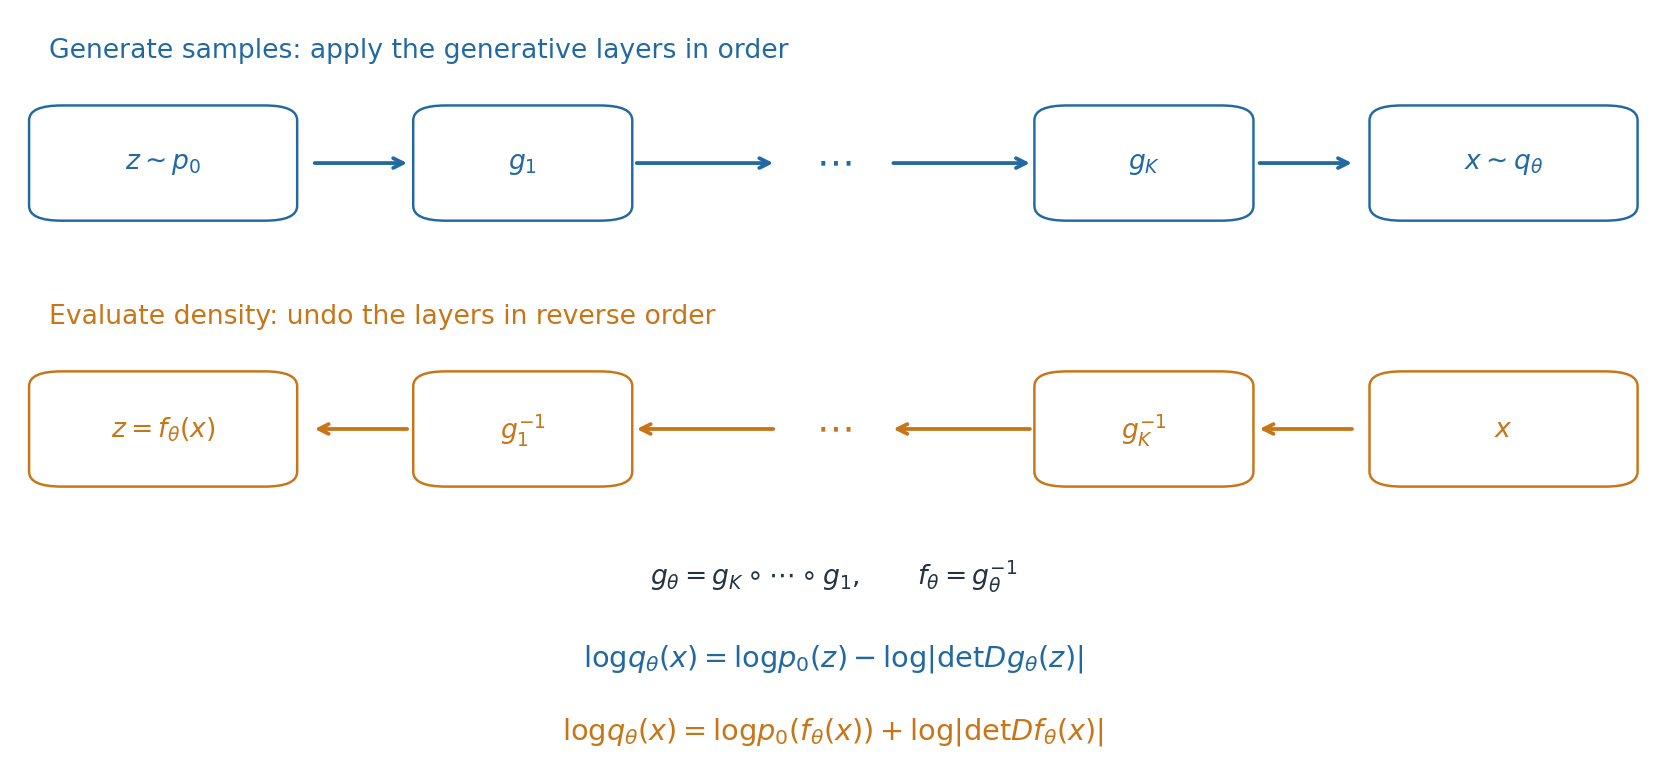

Sampling follows the generating layers. Evaluating a data density follows their inverses in reverse order. The determinant sign belongs to the map that is actually applied.


## Task 3 — A RealNVP distribution

Complete three methods of `RealNVP`:

1. `transform(value, inverse=False)` returns `(output, logdet)` with shapes
   `(B, 2)` and `(B,)`. Reverse the layer order when applying the inverse.
2. `log_prob(x)` encodes data and returns the normalized log density `(B,)`.
3. `sample(n, generator=None)` draws independent base samples, transforms
   them in the generating direction, and returns `(n, 2)` on the model's dtype
   and device. The generator, if provided, must match that device.

Explain why the density is exactly normalized even before training, and why
this does not imply an exact fit to the data distribution or a Bayesian target.


In [ ]:
class RealNVP(nn.Module):
    def __init__(self, n_layers=6, hidden=32):
        super().__init__()
        if n_layers < 1:
            raise ValueError("At least one coupling is required")
        self.layers = nn.ModuleList([
            AffineCoupling([1, 0] if k % 2 == 0 else [0, 1], hidden=hidden)
            for k in range(n_layers)])

    def transform(self, value, inverse=False):
        """Return coordinates (B,2) and applied logdet (B,)."""

        # TODO: initialize per-example logdet, choose order, apply and accumulate.
        raise NotImplementedError("Task 3")

    def log_prob(self, x):
        """x:(B,2) -> normalized log density:(B,)."""
        # TODO: inverse transformation, base log density, inverse logdet.
        raise NotImplementedError("Task 3")

    @torch.no_grad()
    def sample(self, n, generator=None):
        """Return n independent draws with shape (n,2)."""
        # TODO: sample the base on this model's dtype/device and apply g.
        raise NotImplementedError("Task 3")


In [ ]:
def test_flow():
    if not ready(2):
        raise NotImplementedError("Task 2 prerequisite")
    # Noncommuting maps have an explicit two-layer oracle, independent of
    # transform's round-trip consistency: g1=(z1, 2*z2+z1), g2=(3*u1+u2, u2).
    class KnownConditioner(nn.Module):
        def __init__(self, first):
            super().__init__()
            self.first = first
        def forward(self, x):
            zero = torch.zeros_like(x[:, 0])
            if self.first:
                raw = torch.full_like(zero, math.atanh(math.log(2)/1.5))
                return torch.stack([zero, raw, zero, x[:, 0]], dim=1)
            raw = torch.full_like(zero, math.atanh(math.log(3)/1.5))
            return torch.stack([raw, zero, x[:, 1], zero], dim=1)

    known = RealNVP(n_layers=2).double()
    known.layers[0].net = KnownConditioner(True)
    known.layers[1].net = KnownConditioner(False)
    points = torch.tensor([[-0.3, 0.7], [0.5, -0.2]], dtype=torch.float64)
    expected = torch.stack([4*points[:, 0]+2*points[:, 1],
                            points[:, 0]+2*points[:, 1]], dim=1)
    output, ld = known.transform(points)
    assert_close(output, expected)
    assert_close(ld, points.new_full((len(points),), math.log(6)))
    recovered, ild = known.transform(expected, inverse=True)
    assert_close(recovered, points)
    assert_close(ild, -ld)
    assert_close(known.log_prob(expected), standard_normal_log_prob(points) - math.log(6))
    with torch.random.fork_rng():
        torch.manual_seed(13)
        flow = RealNVP(n_layers=4, hidden=12).double()
        z = torch.tensor([[-0.8, 0.3], [0.5, 1.0], [1.2, -0.4]], dtype=torch.float64)
        assert_close(flow.log_prob(z), standard_normal_log_prob(z))  # Initial identity.
        # Perturb every last layer, so composition order and signs matter.
        with torch.no_grad():
            for layer in flow.layers:
                layer.net[-1].weight.normal_(0, 0.12)
                layer.net[-1].bias.normal_(0, 0.15)
        x, ld = flow.transform(z)
        zr, ild = flow.transform(x, inverse=True)
        assert x.shape == z.shape and ld.shape == (len(z),)
        assert_close(zr, z)
        assert_close(ld + ild, torch.zeros_like(ld))
        assert_close(flow.log_prob(x), standard_normal_log_prob(z) - ld)
        for point in z:
            jac = torch.autograd.functional.jacobian(
                lambda v: flow.transform(v[None])[0][0], point)
            reference = torch.linalg.slogdet(jac)[1]
            assert_close(flow.transform(point[None])[1][0], reference)
        g1, g2 = torch.Generator().manual_seed(99), torch.Generator().manual_seed(99)
        draws = flow.sample(7, generator=g1)
        expected = flow.transform(torch.randn(7, 2, generator=g2, dtype=torch.float64))[0]
        assert draws.shape == (7, 2) and draws.dtype == torch.float64
        assert draws.device == next(flow.parameters()).device
        assert_close(draws, expected)
        loss = -flow.log_prob(x.detach()).mean()
        loss.backward()
        assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in flow.parameters())

check_task(3, test_flow)


Your interpretation:

_Write your answer here._


## 4. Learning a density from observations

Suppose observations $x_1,\ldots,x_N$ are drawn from a data distribution
$p_{\rm data}$. Maximum likelihood minimizes mean negative log likelihood:
$$\widehat L_{\rm ML}(\phi)=-\frac1N\sum_{i=1}^N\log q_\phi(x_i).$$
When the relevant expectations exist, its population version is
$$L_{\rm ML}(\phi)=H(p_{\rm data})+
       D_{\rm KL}(p_{\rm data}\Vert q_\phi).$$
The data entropy is constant in $\phi$. The empirical objective approximates
this expectation using observed samples; it does not require knowing their
density. This is density estimation. The weights $\phi$ are optimized
parameters, and fitting a flow this way does not perform Bayesian inference
over those weights.

### A controlled example: noisy moons

Generate two semicircles with equal mixing probabilities and add independent
Gaussian coordinate noise of standard deviation 0.08. The noise makes the
distribution a continuous 2D density, rather than a distribution concentrated
on one-dimensional curves. Class labels color the plots; the flow never uses
them in training.

Use independent training, validation, and test sets. Fit parameters on training
data; select the checkpoint with lowest validation NLL; evaluate the test set
once after selection. A full-covariance Gaussian fitted only to training data
is a useful baseline. All log densities use natural logarithms and the same
original coordinates, so NLL is reported in nats per observation.


In [ ]:
def noisy_moons(n, seed, noise=0.08):
    rng = torch.Generator().manual_seed(seed)
    label = torch.randint(0, 2, (n,), generator=rng)
    angle = math.pi * torch.rand(n, generator=rng)
    upper = torch.stack([torch.cos(angle), torch.sin(angle)], dim=1)
    lower = torch.stack([1 - torch.cos(angle), 0.5 - torch.sin(angle)], dim=1)
    x = torch.where(label[:, None] == 0, upper, lower)
    x = x + noise * torch.randn(n, 2, generator=rng)
    return x.to(device=DEVICE, dtype=DTYPE), label.numpy()

x_train, label_train = noisy_moons(2400, 21)
x_val, label_val = noisy_moons(600, 22)
x_test, label_test = noisy_moons(1000, 23)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, data, labels, title in zip(axes, [x_train, x_val], [label_train, label_val],
                                  ["Training: 2400 observations", "Validation: 600 observations"]):
    values = data.cpu().numpy()
    ax.scatter(values[:, 0], values[:, 1], c=labels, cmap="coolwarm", s=5, alpha=0.6)
    ax.set(xlabel="$x_1$", ylabel="$x_2$", title=title, xlim=(-1.5, 2.5), ylim=(-1, 1.5))
    ax.set_aspect("equal")
plt.tight_layout(); plt.show()

def fit_gaussian(x):
    """Maximum-likelihood mean and covariance; divisor N, not N-1."""
    mean = x.mean(dim=0)
    centered = x - mean
    covariance = centered.T @ centered / len(x)
    return torch.distributions.MultivariateNormal(mean, covariance_matrix=covariance)

gaussian = fit_gaussian(x_train)


### Supplied training loop

Use Adam with minibatches of 256 observations. Every 100 steps, evaluate full
training and validation NLL under the same current parameters. Retain a deep
copy of the best validation checkpoint and restore it before test evaluation.
The test data are never passed to this function. The final loss is allowed to
be negative: a continuous density can have values greater than one.

The model is moved to its device before constructing the optimizer. The
mask is a registered buffer and follows the model's dtype and device. These
details keep exactly the same transform implementation usable on CPU or GPU.


In [ ]:
def train_density(model, train, validation, steps=TRAIN_STEPS, batch_size=256):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    rng = torch.Generator(device=train.device).manual_seed(24)
    history = []
    best_value, best_step, best_state = float("inf"), 0, None
    started = time.perf_counter()
    for step in range(steps + 1):
        if step % 100 == 0 or step == steps:
            model.eval()
            with torch.no_grad():
                train_nll = -model.log_prob(train).mean().item()
                val_nll = -model.log_prob(validation).mean().item()
            history.append((step, train_nll, val_nll))
            if val_nll < best_value:
                best_value, best_step = val_nll, step
                best_state = copy.deepcopy(model.state_dict())
        if step == steps:
            break
        model.train()
        indices = torch.randint(len(train), (batch_size,), generator=rng, device=train.device)
        loss = -model.log_prob(train[indices]).mean()
        if not torch.isfinite(loss):
            raise FloatingPointError("Nonfinite loss: inspect scales and determinants")
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
    model.load_state_dict(best_state)
    model.eval()
    return np.array(history), best_step, time.perf_counter() - started

if ready(2, 3):
    torch.manual_seed(25)
    model = RealNVP(n_layers=6, hidden=32).to(device=DEVICE, dtype=DTYPE)
    history, best_step, elapsed = train_density(model, x_train, x_val)
    print(f"Restored step {best_step}; training took {elapsed:.1f} seconds.")
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(history[:, 0], history[:, 1], label="Training")
    ax.plot(history[:, 0], history[:, 2], label="Validation")
    ax.axvline(best_step, color="0.5", ls="--", label="Selected checkpoint")
    ax.set(xlabel="Optimizer step", ylabel="Mean NLL (nats)", title="Maximum-likelihood training")
    ax.legend(); plt.show()


## 5. Evaluate the distribution, not just its picture

The table reports empirical training, validation, and held-out test NLL.
The test standard error is the sample standard deviation of pointwise test
losses divided by $\sqrt{n_{\rm test}}$, conditional on the fitted model.
Also inspect the paired difference on the same test observations. These
standard errors describe variation across new iid test samples, not training
randomness or the uncertainty of a new training/validation split.

The density plot is evaluated on a finite window. It does not display all
probability mass. Encoded test points should resemble the joint standard
normal if the fit is good. Matching their mean and covariance alone does not
establish normality; normal-looking one-dimensional marginals are also
insufficient to establish the correct joint distribution.


In [ ]:
if ready(2, 3):
    with torch.no_grad():
        test_flow_loss = -model.log_prob(x_test)
        test_gaussian_loss = -gaussian.log_prob(x_test)
        rows = []
        for name, log_prob in [("Gaussian baseline", gaussian.log_prob), ("RealNVP", model.log_prob)]:
            test_losses = -log_prob(x_test)
            rows.append([name, -log_prob(x_train).mean().item(), -log_prob(x_val).mean().item(),
                         test_losses.mean().item(), test_losses.std().item()/math.sqrt(len(x_test))])
        table(["Model", "Train NLL", "Validation NLL", "Test NLL", "Test SE"], rows)
        difference = test_flow_loss - test_gaussian_loss
        table(["Paired test loss difference", "Mean", "SE"],
              [["RealNVP minus Gaussian", difference.mean().item(),
                difference.std().item()/math.sqrt(len(difference))]])
        samples = model.sample(2000, torch.Generator(device=DEVICE).manual_seed(26))
        encoded, inverse_ld = model.transform(x_test, inverse=True)
        # One numerical check after training, with float32 tolerances.
        reconstructed, forward_ld = model.transform(encoded)
        assert_close(reconstructed, x_test, atol=2e-5, rtol=2e-5)
        assert_close(inverse_ld + forward_ld, torch.zeros_like(inverse_ld), atol=2e-5, rtol=2e-5)
    table(["Encoded test diagnostic", "Empirical", "Base reference"],
          [["Mean coordinate 1", encoded[:, 0].mean().item(), 0.0],
           ["Mean coordinate 2", encoded[:, 1].mean().item(), 0.0],
           ["Variance coordinate 1", encoded[:, 0].var().item(), 1.0],
           ["Variance coordinate 2", encoded[:, 1].var().item(), 1.0],
           ["Covariance", torch.cov(encoded.T)[0, 1].item(), 0.0]])

def density_grid(log_prob, xlim, ylim, resolution=150, device=DEVICE, dtype=DTYPE):
    gx = torch.linspace(*xlim, resolution, device=device, dtype=dtype)
    gy = torch.linspace(*ylim, resolution, device=device, dtype=dtype)
    yy, xx = torch.meshgrid(gy, gx, indexing="ij")
    points = torch.stack([xx.reshape(-1), yy.reshape(-1)], dim=-1)
    with torch.no_grad():
        density = log_prob(points).exp().reshape(resolution, resolution)
    return xx.cpu().numpy(), yy.cpu().numpy(), density.cpu().numpy()

if ready(2, 3):
    xx, yy, density = density_grid(model.log_prob, (-1.5, 2.5), (-1, 1.5))
    fig, axes = plt.subplots(1, 4, figsize=(14, 3))
    values = x_test.cpu().numpy()
    axes[0].scatter(values[:, 0], values[:, 1], s=4, c=label_test, cmap="coolwarm", alpha=0.6)
    axes[0].set_title("Held-out observations")
    values = samples.cpu().numpy()
    axes[1].scatter(values[:, 0], values[:, 1], s=4, alpha=0.45)
    axes[1].set_title("Independent flow draws")
    axes[2].contourf(xx, yy, density, levels=25, cmap="Blues")
    axes[2].set_title("Learned density")
    for ax in axes[:3]:
        ax.set(xlabel="$x_1$", ylabel="$x_2$", xlim=(-1.5, 2.5), ylim=(-1, 1.5))
        ax.set_aspect("equal")
    values = encoded.cpu().numpy()
    axes[3].scatter(values[:, 0], values[:, 1], c=label_test, cmap="coolwarm", s=5, alpha=0.55)
    circle_angle = np.linspace(0, 2*np.pi, 300)
    for radius in [1, 2]:
        axes[3].plot(radius*np.cos(circle_angle), radius*np.sin(circle_angle), color="0.4", lw=0.8)
    axes[3].set(xlabel="$z_1$", ylabel="$z_2$", title="Encoded test observations",
                xlim=(-3.5, 3.5), ylim=(-3.5, 3.5), aspect="equal")
    plt.tight_layout(); plt.show()


Interpretation questions. Does the flow improve test NLL relative to the
Gaussian on these observations? What does the paired standard error measure?
Why can increasing the number of generated samples fail to improve the
learned density? Is an encoded sample mean near zero enough to establish fit?


Your interpretation:

_Write your answer here._


## Task 4 — Fit MNIST on a GPU

The two-dimensional example exposes the geometry. Now fit the same kind of
distribution to all 784 pixels of a handwritten digit. The model and training
loop are supplied; your task is to connect an integer image to the continuous
density with the correct change of variables and units.

This extension uses CUDA and `torchvision`. With `RUN_MNIST=True`, completing
Task 4 enables an actual MNIST training run. The default is 12 epochs on 50,000
training images, with 10,000 separate validation images. The official 10,000
test images are evaluated after checkpoint selection. Expect several minutes
on a recent GPU; slower GPUs can take longer. Set the budget before examining
test results. With no CUDA device, the CPU checks still run and training is
explicitly skipped. The earlier tasks remain usable on a CPU.

The first enabled run downloads MNIST through
[torchvision.datasets.MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html).
Later runs reuse the local files. Data and model checkpoints live outside the
seminar folder, under `/tmp/sk_bayes_mnist` by default. Set `NF_MNIST_CACHE`
before running the notebook to choose a persistent cache. The default
`MNIST_RETRAIN=True` performs the fitting task on each enabled run. Set it to
`False` to reuse a matching saved checkpoint for a cached demonstration.

### 6.1 From integer pixels to a continuous density

For an integer image $I\in\{0,\ldots,255\}^{784}$, draw independent
$\varepsilon_j\sim\operatorname{Uniform}(0,1)$ and define
$$u_j=\frac{I_j+\varepsilon_j}{256},\qquad
y_j=\operatorname{logit}(u_j)=\log u_j-\log(1-u_j).$$
Dequantization places a continuous point inside the pixel's bin; dividing by
255 would give the wrong bin width. The uncontracted logit is a bijection
from $(0,1)^{784}$ to $\mathbb R^{784}$, with
$$\log\left|\det\frac{\partial y}{\partial u}\right|
=\sum_{j=1}^{784}[-\log u_j-\log(1-u_j)].$$
Our high-dimensional flow generates logits, $y=g_\phi(z)$. Its supplied
`log_prob(y)` returns $\log q_y(y)$, including the flow's own determinants.
Thus
$$\log q_u(u)=\log q_y(y)
 +\sum_j[-\log u_j-\log(1-u_j)].$$

The corresponding discrete model assigns each integer image the probability
mass of its bin. Jensen's inequality gives
$$\log P_\phi(I)=\log\!\int_{[0,1)^{784}}
\frac{q_u((I+\varepsilon)/256)}{256^{784}}\,d\varepsilon
\;\ge\;\mathbb E_\varepsilon[\log q_u(u)]-784\log256.$$
The expected dequantized negative log score is an upper bound on the exact
discrete NLL. A single noise draw is a Monte Carlo estimator of that bound,
and need not itself bound the exact NLL. Report bits per dimension as
$$\operatorname{bpd}(I,\varepsilon)
=\frac{-\log q_y(y)-\log|\det(\partial y/\partial u)|+784\log256}
       {784\log2}.$$
This explains the extra 8 bits per pixel. A continuous log density at a point
is not the exact probability of an integer image.

Noise and logit preprocessing use float64 to avoid rounding a bright pixel
to $u=1$ before taking its logarithm. Exact zero draws are redrawn. Logits
are then cast to the model's dtype. We do not clip image values or contract
their support; the generative image map is simply $u=\operatorname{sigmoid}(y)$.


In [ ]:
from pathlib import Path
import os

MNIST_CACHE = Path(os.environ.get("NF_MNIST_CACHE", "/tmp/sk_bayes_mnist"))
MNIST_EPOCHS = 12
MNIST_BATCH_SIZE = 256
MNIST_LAYERS = 10
MNIST_HIDDEN = 512
MNIST_RETRAIN = True
MNIST_DIM = 28 * 28
mnist_enabled = False

def mnist_uniform(shape, device, generator):
    """Numerically open Uniform(0,1), kept in float64 for image preprocessing."""
    noise = torch.rand(shape, dtype=torch.float64, device=device, generator=generator)
    zero = noise == 0
    while zero.any():
        noise[zero] = torch.rand((int(zero.sum()),), dtype=torch.float64,
                                device=device, generator=generator)
        zero = noise == 0
    return noise

def mnist_preprocess(images, noise):
    """Supplied: integer pixels -> float64 (logits, log|dy/du|)."""
    u = (images.to(torch.float64) + noise.to(torch.float64)) / 256.0
    y = torch.log(u) - torch.log1p(-u)
    logdet = (-torch.log(u) - torch.log1p(-u)).flatten(1).sum(dim=1)
    return y.flatten(1), logdet


Complete `mnist_nll_terms(model, images, noise)`.

1. Use the supplied preprocessing, then cast the logits to the model's dtype
   and device. `images` is a uint8 tensor `(B,1,28,28)`; `noise` has the same
   shape and contains values strictly between zero and one.
2. Evaluate `model.log_prob(y)`. Add the preprocessing log determinant to
   obtain the density in $u$ coordinates. Include the $784\log256$ bin-width
   correction when forming `nll_nats`.
3. Return `(nll_nats, bits_per_dim)`, each `(B,)`. Here `nll_nats` is the
   dequantized discrete-NLL estimator in nats, not the continuous NLL alone.
   Preserve gradients through the model; the training objective will be the
   mean of `bits_per_dim`.

The CPU checks include a model whose implied pixel density is uniform. Its
answer is exactly 8 bpd for every image, including zero and 255-valued pixels.
This checks both the logit Jacobian and the bin-width correction.


In [ ]:
def mnist_nll_terms(model, images, noise):
    """Return dequantized (nll_nats:(B,), bits_per_dim:(B,))."""
    # TODO: logit preprocessing, model density, Jacobian, and discrete units.
    raise NotImplementedError("Task 4")


In [ ]:
def test_mnist_objective():
    class UniformPixelOracle(nn.Module):
        def __init__(self):
            super().__init__()
            self.offset = nn.Parameter(torch.tensor(0., dtype=torch.float64))
        def log_prob(self, y):
            # Independent standard logistic logits imply uniform pixel values.
            return (-torch.nn.functional.softplus(y)
                    -torch.nn.functional.softplus(-y)).sum(dim=1) + self.offset

    oracle = UniformPixelOracle()
    images = torch.stack([torch.zeros(1, 28, 28),
                          torch.full((1, 28, 28), 255),
                          torch.arange(784).remainder(256).reshape(1, 28, 28)]).to(torch.uint8)
    noise = torch.linspace(0.001, 0.999, images.numel(), dtype=torch.float64).reshape(images.shape)
    nll, bpd = mnist_nll_terms(oracle, images, noise)
    assert nll.shape == bpd.shape == (3,)
    assert nll.dtype == bpd.dtype == torch.float64 and nll.device.type == "cpu"
    assert_close(nll, torch.full_like(nll, 784 * math.log(256)), atol=2e-9)
    assert_close(bpd, torch.full_like(bpd, 8.0), atol=1e-10)
    grad, = torch.autograd.grad(bpd.mean(), oracle.offset)
    assert_close(grad, grad.new_tensor(-1 / (784 * math.log(2))))

    class NormalLogitOracle(nn.Module):
        def __init__(self):
            super().__init__()
            self.anchor = nn.Parameter(torch.tensor(0., dtype=torch.float64))
        def log_prob(self, y):
            return -0.5 * (y.square() + math.log(2*math.pi)).sum(dim=1) + self.anchor

    normal = NormalLogitOracle()
    nll, bpd = mnist_nll_terms(normal, images, noise)
    u = (images.double() + noise) / 256
    y = torch.log(u / (1-u)).flatten(1)
    reference = (0.5 * (y.square() + math.log(2*math.pi)).sum(dim=1)
                 + (torch.log(u) + torch.log1p(-u)).flatten(1).sum(dim=1)
                 + 784 * math.log(256))
    assert_close(nll, reference, atol=1e-8)
    assert_close(bpd, reference / (784 * math.log(2)), atol=1e-10)
    assert torch.isfinite(nll).all()
    print("Uniform pixel density: 8 bpd; normal-logit oracle and model gradient: correct.")

check_task(4, test_mnist_objective)


### 6.2 A supplied 784-dimensional RealNVP

Each layer preserves one half of a flattened 28 by 28 checkerboard and
transforms the other half. The masks alternate. Its conditioner is an MLP
with two hidden layers of width 512 and SiLU activations; the final layer
starts at zero. The log scale is bounded by $1.5\tanh(s_{\rm raw})$.

A final generating affine map $y=\mu+\exp(a)\odot h$ learns a separate location
and scale for every pixel in logit space. Its initial moments use a subset
of training images only. Its log determinant $\sum_j a_j$ is part of the
model density. This gives the couplings a useful starting coordinate system
without fitting any preprocessing parameter on validation or test images.
This compact MLP model is an educational image flow; the original RealNVP
image architecture also uses convolutional networks and multiple scales.


In [ ]:
class MNISTCoupling(nn.Module):
    def __init__(self, mask, hidden=512):
        super().__init__()
        self.register_buffer("mask", mask.float().reshape(1, -1))
        self.net = nn.Sequential(nn.Linear(MNIST_DIM, hidden), nn.SiLU(),
                                 nn.Linear(hidden, hidden), nn.SiLU(),
                                 nn.Linear(hidden, 2*MNIST_DIM))
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def transform(self, value, inverse=False):
        preserved = self.mask * value
        raw_s, raw_t = self.net(preserved).chunk(2, dim=-1)
        s = 1.5 * torch.tanh(raw_s) * (1-self.mask)
        t = raw_t * (1-self.mask)
        if inverse:
            output = preserved + (1-self.mask) * (value-t) * torch.exp(-s)
            return output, -s.sum(dim=-1)
        output = preserved + (1-self.mask) * (value*torch.exp(s)+t)
        return output, s.sum(dim=-1)

class MNISTRealNVP(nn.Module):
    def __init__(self, n_layers=10, hidden=512):
        super().__init__()
        row, column = torch.meshgrid(torch.arange(28), torch.arange(28), indexing="ij")
        checkerboard = ((row + column) % 2).flatten()
        self.layers = nn.ModuleList([
            MNISTCoupling(checkerboard if k % 2 == 0 else 1-checkerboard, hidden)
            for k in range(n_layers)])
        self.location = nn.Parameter(torch.zeros(MNIST_DIM))
        self.log_scale = nn.Parameter(torch.zeros(MNIST_DIM))

    @torch.no_grad()
    def initialize(self, training_logits):
        self.location.copy_(training_logits.mean(dim=0))
        self.log_scale.copy_(training_logits.std(dim=0).clamp_min(0.1).log())

    def transform(self, value, inverse=False):
        if inverse:
            value = (value-self.location) * torch.exp(-self.log_scale)
            logdet = -self.log_scale.sum().expand(len(value))
            for layer in reversed(self.layers):
                value, delta = layer.transform(value, inverse=True)
                logdet = logdet + delta
            return value, logdet
        logdet = value.new_zeros(len(value))
        for layer in self.layers:
            value, delta = layer.transform(value)
            logdet = logdet + delta
        return self.location + torch.exp(self.log_scale)*value, logdet+self.log_scale.sum()

    def log_prob(self, logits):
        z, inverse_logdet = self.transform(logits, inverse=True)
        return standard_normal_log_prob(z) + inverse_logdet

    @torch.no_grad()
    def sample_images(self, n, generator=None, temperature=1.0):
        parameter = self.location
        z = torch.randn(n, MNIST_DIM, generator=generator,
                        device=parameter.device, dtype=parameter.dtype)
        logits, _ = self.transform(temperature*z)
        return torch.sigmoid(logits).reshape(n, 1, 28, 28)

def test_mnist_supplied_model():
    # Small CPU model: nonzero couplings plus a nontrivial final affine map.
    with torch.random.fork_rng():
        torch.manual_seed(400)
        model = MNISTRealNVP(n_layers=2, hidden=12).double()
        with torch.no_grad():
            model.location.normal_(0, 0.1)
            model.log_scale.uniform_(-0.2, 0.2)
            for layer in model.layers:
                layer.net[-1].weight.normal_(0, 0.01)
                layer.net[-1].bias.normal_(0, 0.02)
        z = torch.randn(2, MNIST_DIM, dtype=torch.float64)
        y, ld = model.transform(z)
        recovered, inverse_ld = model.transform(y, inverse=True)
        assert_close(recovered, z)
        assert_close(ld+inverse_ld, torch.zeros_like(ld))
        assert_close(model.log_prob(y), standard_normal_log_prob(z)-ld)
    print("Supplied image flow: round trip, affine determinant, and density identity passed.")

test_mnist_supplied_model()


### 6.3 Data, validation, and GPU training

Shuffle the official training set once with a fixed seed, then reserve 10,000
images for validation. Use fresh dequantization noise for each training batch
and a fixed independent noise draw for each validation image. Select the
lowest validation-bpd checkpoint. The test set and its fixed noise draw are
used after selection. Digit labels are used only in the visualizations.

The training curve averages fresh-noise minibatch scores collected while
parameters change within an epoch. Validation scores evaluate a fixed model
and fixed noise. Their small fluctuations need not match. A saved checkpoint
also records the configuration, history, and selected epoch. Changing the
configuration starts a new training run rather than silently reusing it.


In [ ]:
@torch.no_grad()
def mnist_scores(model, images, noise, batch_size=512):
    model.eval()
    scores = []
    for start in range(0, len(images), batch_size):
        _, bpd = mnist_nll_terms(model, images[start:start+batch_size],
                               noise[start:start+batch_size])
        scores.append(bpd.detach().cpu().double())
    return torch.cat(scores)

def mnist_train_or_load(model, training, validation, validation_noise, config):
    checkpoint_path = MNIST_CACHE / "mnist_realnvp_v1.pt"
    if checkpoint_path.exists() and not MNIST_RETRAIN:
        saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        if saved.get("config") == config:
            model.load_state_dict(saved["state_dict"])
            model.eval()
            print(f"Loaded validation-selected checkpoint: {checkpoint_path}")
            return saved["history"], saved["best_epoch"], saved["elapsed_seconds"]
        print("Cached configuration differs; training the requested model.")

    parameter = model.location
    rng = torch.Generator(device=parameter.device).manual_seed(404)
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,
                        T_max=MNIST_EPOCHS, eta_min=5e-5)
    initial = mnist_scores(model, validation, validation_noise).mean().item()
    best_value, best_epoch = initial, 0
    best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
    history = [[0, float("nan"), initial]]
    torch.cuda.synchronize()
    started = time.perf_counter()
    for epoch in range(1, MNIST_EPOCHS+1):
        model.train()
        order = torch.randperm(len(training), generator=rng, device=parameter.device)
        total, count = 0.0, 0
        for start in range(0, len(training), MNIST_BATCH_SIZE):
            images = training[order[start:start+MNIST_BATCH_SIZE]]
            noise = mnist_uniform(images.shape, parameter.device, rng)
            _, bpd = mnist_nll_terms(model, images, noise)
            loss = bpd.mean()
            if not torch.isfinite(loss):
                raise FloatingPointError("Nonfinite MNIST loss; inspect logit inputs and scales")
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            total += loss.item()*len(images)
            count += len(images)
        scheduler.step()
        value = mnist_scores(model, validation, validation_noise).mean().item()
        history.append([epoch, total/count, value])
        if value < best_value:
            best_value, best_epoch = value, epoch
            best_state = {name: tensor.detach().cpu().clone()
                          for name, tensor in model.state_dict().items()}
        print(f"Epoch {epoch:2d}/{MNIST_EPOCHS}: train {total/count:.4f}, validation {value:.4f} bpd")
    torch.cuda.synchronize()
    elapsed = time.perf_counter()-started
    model.load_state_dict(best_state)
    model.eval()
    MNIST_CACHE.mkdir(parents=True, exist_ok=True)
    temporary = checkpoint_path.with_suffix(".tmp")
    torch.save({"config": config, "state_dict": best_state, "history": history,
                "best_epoch": best_epoch, "elapsed_seconds": elapsed}, temporary)
    temporary.replace(checkpoint_path)
    print(f"Selected epoch {best_epoch}; GPU training took {elapsed/60:.2f} minutes.")
    return history, best_epoch, elapsed

if not RUN_MNIST:
    print("MNIST training disabled: set RUN_MNIST=True to enable the GPU extension.")
elif not ready(4):
    print("MNIST training skipped until Task 4 passes its CPU checks.")
elif not torch.cuda.is_available():
    print("MNIST GPU extension skipped: no CUDA device. Task 4 CPU checks remain available.")
else:
    from torchvision.datasets import MNIST
    mnist_device = torch.device("cuda")
    torch.set_float32_matmul_precision("high")
    torch.manual_seed(401)
    train_source = MNIST(str(MNIST_CACHE / "data"), train=True, download=True)
    test_source = MNIST(str(MNIST_CACHE / "data"), train=False, download=True)
    split = torch.randperm(len(train_source), generator=torch.Generator().manual_seed(402))
    mnist_train = train_source.data[split[:50000], None].to(mnist_device)
    mnist_validation = train_source.data[split[50000:], None].to(mnist_device)
    mnist_test = test_source.data[:, None].to(mnist_device)
    mnist_test_labels = test_source.targets
    validation_rng = torch.Generator(device=mnist_device).manual_seed(403)
    mnist_validation_noise = mnist_uniform(mnist_validation.shape, mnist_device, validation_rng)
    mnist_model = MNISTRealNVP(MNIST_LAYERS, MNIST_HIDDEN).to(mnist_device)
    initialization_rng = torch.Generator(device=mnist_device).manual_seed(405)
    initial_images = mnist_train[:8192]
    initial_noise = mnist_uniform(initial_images.shape, mnist_device, initialization_rng)
    initial_logits, _ = mnist_preprocess(initial_images, initial_noise)
    mnist_model.initialize(initial_logits.float())
    del initial_logits, initial_noise
    mnist_config = {"version": 1, "epochs": MNIST_EPOCHS, "layers": MNIST_LAYERS,
                    "hidden": MNIST_HIDDEN, "batch_size": MNIST_BATCH_SIZE,
                    "split_seed": 402, "validation_noise_seed": 403,
                    "training_seed": 404, "initialization_seed": 405,
                    "learning_rate": 5e-4, "dequantization": "open_uniform_exact_logit"}
    print(f"GPU: {torch.cuda.get_device_name(0)}; parameters: "
          f"{sum(p.numel() for p in mnist_model.parameters()):,}")
    mnist_history, mnist_best_epoch, mnist_elapsed = mnist_train_or_load(
        mnist_model, mnist_train, mnist_validation, mnist_validation_noise, mnist_config)
    # Test evaluation begins only after model selection and restoration.
    test_rng = torch.Generator(device=mnist_device).manual_seed(406)
    mnist_test_noise = mnist_uniform(mnist_test.shape, mnist_device, test_rng)
    mnist_test_bpd = mnist_scores(mnist_model, mnist_test, mnist_test_noise)
    table(["MNIST quantity", "Value"],
          [["Training images", len(mnist_train)], ["Validation images", len(mnist_validation)],
           ["Test images", len(mnist_test)], ["Selected epoch", mnist_best_epoch],
           ["Test dequantized bpd", mnist_test_bpd.mean().item()],
           ["Test SE across images / fixed noise draws", mnist_test_bpd.std().item()/math.sqrt(len(mnist_test_bpd))]])
    mnist_enabled = True


### 6.4 Inspect what was learned

Read the held-out dequantized score together with the samples. The grids below
show consecutive held-out images and unfiltered independent model draws.
There is no class conditioning or rejection of unattractive samples.
The compact model may produce incomplete or ambiguous digits; likelihood and
visual quality diagnose different aspects of fit.


In [ ]:
def mnist_mosaic(images, columns=8, gap=2):
    """Display-only tiling; every panel uses the same grayscale limits."""
    images = images.detach().cpu().reshape(-1, 28, 28).numpy()
    rows = math.ceil(len(images)/columns)
    canvas = np.zeros((rows*28+(rows-1)*gap, columns*28+(columns-1)*gap))
    for index, image in enumerate(images):
        row, column = divmod(index, columns)
        canvas[row*(28+gap):row*(28+gap)+28, column*(28+gap):column*(28+gap)+28] = image
    return canvas

def mnist_show(ax, images, title, columns=8):
    ax.imshow(mnist_mosaic(images, columns), cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(title, fontsize=11)
    ax.axis("off")

if mnist_enabled:
    history = np.asarray(mnist_history)
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(history[1:, 0], history[1:, 1], color="#2369a1", label="Training: online / fresh noise")
    ax.plot(history[:, 0], history[:, 2], color="#c77516", label="Validation: fixed noise")
    ax.axvline(mnist_best_epoch, color="0.5", ls="--", label="Selected epoch")
    ax.set(xlabel="Epoch", ylabel="Dequantized bits per dimension", title="Full 28 × 28 MNIST density fitting")
    ax.legend(fontsize=9); plt.tight_layout(); plt.show()

    draw_rng = torch.Generator(device=mnist_device).manual_seed(407)
    mnist_generated = mnist_model.sample_images(32, generator=draw_rng)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    mnist_show(axes[0], mnist_test[:32].float()/255, "Held-out MNIST observations")
    mnist_show(axes[1], mnist_generated, "Independent samples from the fitted flow")
    plt.tight_layout(); plt.show()


Temperature changes the distribution: replacing $z\sim\mathcal N(0,I)$ by
$Tz$ uses the base $\mathcal N(0,T^2I)$. Only $T=1$ samples the model whose
likelihood was evaluated above. Using the same base draws across rows makes
the visual effect easier to compare. A lower temperature can make some
images look cleaner while reducing diversity; it does not improve the
reported likelihood of the original model.


In [ ]:
if mnist_enabled:
    fig, axes = plt.subplots(3, 1, figsize=(10, 4.5))
    for ax, temperature in zip(axes, [0.65, 0.85, 1.0]):
        rng = torch.Generator(device=mnist_device).manual_seed(408)
        draws = mnist_model.sample_images(12, generator=rng, temperature=temperature)
        label = "fitted model" if temperature == 1 else "changed base distribution"
        mnist_show(ax, draws, f"T = {temperature:g}: {label}", columns=12)
    plt.tight_layout(); plt.show()


Latent interpolation is another view of the learned map. Encode two held-out
images, interpolate linearly between their latent vectors, and decode the path.
The endpoints are supplied observations, and the intermediate images are a
deterministic path. These are not independent generated samples. Linear
interpolation can also pass through atypical latent regions, so a smooth
visual transition is not a proof of a good density model.


In [ ]:
if mnist_enabled:
    with torch.no_grad():
        interpolation_logits, _ = mnist_preprocess(mnist_test[:100], mnist_test_noise[:100])
        interpolation_z, _ = mnist_model.transform(interpolation_logits.float(), inverse=True)
        t = torch.linspace(0, 1, 9, device=mnist_device)[:, None]
        fig, axes = plt.subplots(3, 1, figsize=(10, 4.5))
        for ax, (first, second) in zip(axes, [(0, 1), (2, 3), (4, 5)]):
            path = (1-t)*interpolation_z[first] + t*interpolation_z[second]
            logits, _ = mnist_model.transform(path)
            digits = torch.sigmoid(logits).reshape(-1, 1, 28, 28)
            a, b = int(mnist_test_labels[first]), int(mnist_test_labels[second])
            mnist_show(ax, digits, f"Encoded held-out {a} → {b}: deterministic latent interpolation", columns=9)
        plt.tight_layout(); plt.show()


Finally, check numerical inversion separately from generation. Passing an
observed, dequantized image through $f_\phi$ and back through $g_\phi$ should
recover that same continuous image. This follows from the architecture, even
for a poorly trained model. Training uses float32 with accelerated matrix
multiplication; this small diagnostic uses a float64 copy of the fitted
weights to check inversion without reduced-precision matrix products.
The error map uses its own color scale to make tiny floating-point errors
visible; it is not a sample-quality metric.


In [ ]:
if mnist_enabled:
    with torch.no_grad():
        observed = mnist_test[:8]
        noise = mnist_test_noise[:8]
        logits64, _ = mnist_preprocess(observed, noise)
        diagnostic_model = copy.deepcopy(mnist_model).double()
        z, inverse_ld = diagnostic_model.transform(logits64, inverse=True)
        recovered_logits, forward_ld = diagnostic_model.transform(z)
        original_u = (observed.double()+noise)/256
        recovered_u = torch.sigmoid(recovered_logits).reshape_as(original_u)
        pixel_error = (recovered_u-original_u).abs()
        max_error = pixel_error.max().item()
        assert max_error < 2e-10
        assert_close(recovered_logits, logits64, atol=1e-9, rtol=1e-9)
        assert_close(inverse_ld+forward_ld, torch.zeros_like(inverse_ld), atol=1e-8, rtol=0)
    table(["Numerical inversion diagnostic (float64)", "Maximum absolute error"],
          [["Pixel value in [0,1]", max_error],
           ["Logit coordinate", (recovered_logits-logits64).abs().max().item()],
           ["Forward + inverse log determinant", (inverse_ld+forward_ld).abs().max().item()]])
    fig, axes = plt.subplots(3, 1, figsize=(10, 4.8))
    mnist_show(axes[0], original_u, "Input: held-out images with fixed dequantization noise", columns=8)
    mnist_show(axes[1], recovered_u, "Reconstructed with float64 inverse and generating maps", columns=8)
    errors = mnist_mosaic(pixel_error, columns=8, gap=0)
    im = axes[2].imshow(errors, cmap="magma", vmin=0,
                       vmax=max(max_error, torch.finfo(torch.float64).eps), interpolation="nearest")
    axes[2].set_title("Absolute pixel error: magnified color scale", fontsize=11)
    axes[2].axis("off")
    fig.colorbar(im, ax=axes[2], fraction=0.018, pad=0.02, label="Absolute error")
    plt.tight_layout(); plt.show()
    del diagnostic_model


Interpretation questions. Why does the score need both the logit determinant
and the 8-bit bin correction? What changes when a sample is drawn at $T<1$?
Why can reconstruction be almost perfect while independent samples are poor?
Which errors does the reported test SE measure, and which does it omit?


Your interpretation:

_Write your answer here._


## 7. What the four tasks establish

The affine example fixes the direction and determinant sign. Coupling makes
nonlinear transformations invertible with a cheap determinant. Composition
builds a richer distribution while keeping density evaluation and independent
sampling tractable. The MNIST task extends the same calculations to 784 pixels,
including the treatment of discrete observations and image-level evaluation.
Training changes the represented density without changing these normalization
identities.

Before moving to the appendix, explain the difference between:

- Exact evaluation of the model density and an exact match to the target.
- Independent draws from a fixed learned flow and correlated MCMC states.
- Learning from observed target samples and approximating an unnormalized
  posterior using only its log density.

The last distinction determines the training objective in Appendix A.


## Appendix A. A flow as a variational approximation

### A.1 A posterior-shaped target with a known reference

Use a curved two-dimensional target to separate approximation error from
Monte Carlo error. This is an analytically specified benchmark, rather than
the posterior of a fitted data model. Let
$$Z_1,Z_2\overset{\rm iid}\sim\mathcal N(0,1),\qquad
\theta_1=Z_1,\quad\theta_2=b(Z_1^2-1)+\sigma Z_2,$$
with $b=0.8$ and $\sigma=0.45$. Its density is
$$\pi(\theta)=\frac1{2\pi\sigma}
\exp\left[-\frac{\theta_1^2}2-
\frac{[\theta_2-b(\theta_1^2-1)]^2}{2\sigma^2}\right].$$
The exact map above is used only for reference samples and analytic checks;
the learned flow receives a callable target log density during optimization.

Using $\mathbb E Z_1^2=1$, $\mathbb E Z_1^3=0$, and $\mathbb E Z_1^4=3$ gives
$$\mathbb E_\pi[\theta]=(0,0),\qquad
\operatorname{Cov}_\pi(\theta)=
\begin{pmatrix}1&0\\0&2b^2+\sigma^2\end{pmatrix}.$$
Zero covariance does not imply independence: the conditional mean of $\theta_2$
is curved. The unique mode is $(0,-b)$. At the mode the negative log density
has Hessian $\operatorname{diag}(1,\sigma^{-2})$, so Laplace gives
$$q_{\rm L}=\mathcal N\!\left((0,-b),\operatorname{diag}(1,\sigma^2)\right).$$
Its center and second variance differ substantially from the exact moments.
This exposes the local nature of the Hessian approximation.

### A.2 The reverse-KL objective

For a general posterior $\pi(\theta)=\widetilde\pi(\theta)/Z$,
$$D_{\rm KL}(q_\phi\Vert\pi)
=\mathbb E_{q_\phi}[\log q_\phi(\theta)-\log\widetilde\pi(\theta)]+\log Z.$$
Since $Z$ does not depend on the variational parameters, minimize
$$L_{\rm VI}(\phi)=\mathbb E_{z\sim p_0}
\left[\log p_0(z)-\log|\det Dg_\phi(z)|
      -\log\widetilde\pi(g_\phi(z))\right].$$
This is reverse KL, $D_{\rm KL}(q_\phi\Vert\pi)$, whereas population density
MLE minimizes forward KL, $D_{\rm KL}(p_{\rm data}\Vert q_\phi)$.
The two expectations use different sampling distributions. Their different
penalties matter, but labels such as “mode seeking” are not universal guarantees
about an architecture or a finite optimization run.

The ELBO is $-L_{\rm VI}$ when $\widetilde\pi$ is the actual likelihood times
prior. Its value depends on constants in that joint density. Adding a constant
to a target log kernel changes the objective value but not its gradient in $\phi$.
Our benchmark uses a normalized target, so the evaluation KL below is directly
estimable; no unknown evidence is being estimated.

Gradients must pass through both $g_\phi(z)$ and the log determinant. The
`sample` helper intentionally disables gradients; use `transform(z)` during VI.


In [ ]:
BEND, BANANA_SCALE = 0.8, 0.45

def banana_log_prob(theta):
    residual = (theta[:, 1] - BEND * (theta[:, 0].square() - 1)) / BANANA_SCALE
    return -math.log(2*math.pi*BANANA_SCALE) - 0.5*(theta[:, 0].square() + residual.square())

def banana_sample(n, seed):
    rng = torch.Generator(device=DEVICE).manual_seed(seed)
    z = torch.randn(n, 2, generator=rng, device=DEVICE, dtype=DTYPE)
    return torch.stack([z[:, 0], BEND*(z[:, 0].square()-1)+BANANA_SCALE*z[:, 1]], dim=1)

def train_variational(model, steps=VI_STEPS, batch_size=512):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    parameter = next(model.parameters())
    rng = torch.Generator(device=parameter.device).manual_seed(31)
    history = []
    for step in range(steps):
        z = torch.randn(batch_size, 2, generator=rng, device=parameter.device, dtype=parameter.dtype)
        theta, logdet = model.transform(z)  # Keep the reparameterization graph.
        log_q = standard_normal_log_prob(z) - logdet
        loss = (log_q - banana_log_prob(theta)).mean()
        if not torch.isfinite(loss):
            raise FloatingPointError("Nonfinite variational objective")
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        if step % 100 == 0 or step == steps-1:
            history.append((step, loss.item()))
    model.eval()
    return np.array(history)

if RUN_APPENDICES and ready(2, 3):
    torch.manual_seed(32)
    vi_model = RealNVP(n_layers=6, hidden=32).to(device=DEVICE, dtype=DTYPE)
    vi_history = train_variational(vi_model)
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(vi_history[:, 0], vi_history[:, 1], marker=".")
    ax.set(xlabel="Optimizer step", ylabel="Minibatch estimate", title="Reverse-KL training objective")
    plt.show()


### A.3 Compare Laplace, the learned flow, and the reference

Use new draws after training. Report moments, the event probability
$\Pr(\theta_2>1)$, and $\mathbb E_q[\log q-\log\pi]$. This last quantity is KL
for each normalized approximation; it is zero for the exact target. Its finite
Monte Carlo estimate can be slightly negative even though KL is nonnegative.
The SE is computed from iid integrand values at fixed fitted parameters.

For Laplace there is also an analytic check. Under $q_{\rm L}$,
$\theta_1=Z_1$, $\theta_2=-b+\sigma Z_2$, so
$\log(q_{\rm L}/\pi)=-bZ_1^2Z_2/\sigma+b^2Z_1^4/(2\sigma^2)$.
Its expectation is $3b^2/(2\sigma^2)$.

The Laplace event probability is $1-\Phi(4)\approx3.17\times10^{-5}$, so
20,000 draws contain only 0.63 expected events. A run with no events prints
zero for both the empirical probability and its plug-in SE. Those zeros do
not establish zero probability or the absence of Monte Carlo uncertainty.
For an additional target reference, integrate the conditional event probability
over $Z_1$ using one-dimensional Gauss–Hermite quadrature:
$$\Pr_\pi(\theta_2>1)=\mathbb E_{Z_1}
\left[\Phi\!\left(\frac{b(Z_1^2-1)-1}{\sigma}\right)\right].$$
The table labels this numerical reference separately from analytic moments.

More flow samples improve numerical estimates under $q_\phi$, but do not
remove the discrepancy between $q_\phi$ and $\pi$. For an actual posterior,
this distinction also applies to posterior-predictive expectations.


In [ ]:
if RUN_APPENDICES and ready(2, 3):
    laplace = torch.distributions.MultivariateNormal(
        torch.tensor([0., -BEND], device=DEVICE, dtype=DTYPE),
        covariance_matrix=torch.diag(torch.tensor([1., BANANA_SCALE**2], device=DEVICE, dtype=DTYPE)))
    exact_variance2 = 2*BEND**2 + BANANA_SCALE**2
    # Gauss-Hermite weights integrate exp(-u^2); Z_1=sqrt(2)*u.
    nodes, weights = np.polynomial.hermite.hermgauss(320)
    conditional_tail = np.array([
        0.5*math.erfc((1-BEND*(2*u*u-1))/(BANANA_SCALE*math.sqrt(2)))
        for u in nodes])
    target_event_quadrature = np.dot(weights, conditional_tail)/math.sqrt(math.pi)
    laplace_event_exact = 0.5*math.erfc((1+BEND)/(BANANA_SCALE*math.sqrt(2)))
    # Verify the Hessian calculation independently of the learned model.
    mode = torch.tensor([0., -BEND], device=DEVICE, dtype=torch.float64)
    hessian = torch.autograd.functional.hessian(lambda t: -banana_log_prob(t[None])[0], mode)
    assert_close(hessian, torch.diag(mode.new_tensor([1., BANANA_SCALE**-2])))
    with torch.no_grad():
        reference = banana_sample(20000, 33)
        flow_draws = vi_model.sample(20000, torch.Generator(device=DEVICE).manual_seed(34))
        z = torch.randn(20000, 2, generator=torch.Generator(device=DEVICE).manual_seed(35),
                        device=DEVICE, dtype=DTYPE)
        laplace_draws = z * z.new_tensor([1., BANANA_SCALE]) + z.new_tensor([0., -BEND])
        rows = []
        for name, draws, log_prob in [("Exact target draws", reference, banana_log_prob),
                                      ("Laplace", laplace_draws, laplace.log_prob),
                                      ("VI flow", flow_draws, vi_model.log_prob)]:
            log_ratio = log_prob(draws) - banana_log_prob(draws)
            event = (draws[:, 1] > 1).to(draws.dtype)
            rows.append([name, draws[:, 0].mean().item(), draws[:, 1].mean().item(),
                         draws[:, 1].var().item(), event.mean().item(),
                         event.std().item()/math.sqrt(len(draws)), log_ratio.mean().item(),
                         log_ratio.std().item()/math.sqrt(len(draws))])
        table(["Distribution", "Mean 1", "Mean 2", "Variance 2", "P(theta2>1)", "Event MC SE", "KL estimate", "KL MC SE"], rows)
        table(["Reference", "Value"],
              [["Target mean 2", 0.0], ["Target variance 2", exact_variance2],
               ["Laplace mean 2", -BEND], ["Laplace variance 2", BANANA_SCALE**2],
               ["Laplace KL to target", 3*BEND**2/(2*BANANA_SCALE**2)],
               ["Target event (320-node quadrature)", target_event_quadrature],
               ["Laplace event (analytic)", laplace_event_exact]])
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    for ax, draws, log_prob, title in zip(axes, [reference, laplace_draws, flow_draws],
                                        [banana_log_prob, laplace.log_prob, vi_model.log_prob],
                                        ["Exact curved target", "Laplace approximation", "Variational flow"]):
        xx, yy, density = density_grid(log_prob, (-3, 3), (-2, 5))
        ax.contour(xx, yy, density, levels=[0.01, 0.05, 0.15, 0.3], colors="0.35", linewidths=0.7)
        values = draws[:1800].cpu().numpy()
        ax.scatter(values[:, 0], values[:, 1], s=3, alpha=0.3)
        ax.set(xlabel=r"$\theta_1$", ylabel=r"$\theta_2$", title=title,
               xlim=(-3, 3), ylim=(-2, 5))
    plt.tight_layout(); plt.show()


Interpretation questions. Why is the target mean different from its mode?
Which approximation reproduces the curved mass in this run? Does a small
estimated reverse KL guarantee that every rare-event probability is accurate?
What information would be unavailable for a real posterior with unknown $Z$?


Your interpretation:

_Write your answer here._


## Appendix B. Masks, support, and limits

### B.1 What happens when masks never change?

If all layers preserve coordinate 1, then $X_1=Z_1$ for every generated point.
The first marginal remains exactly standard normal, irrespective of training.
The optional experiment verifies this identity for nonzero transformations.
Alternating masks removes this specific obstruction; it is not a guarantee
that a chosen finite network can fit every target to arbitrary precision.


In [ ]:
if RUN_APPENDICES and ready(2, 3):
    with torch.random.fork_rng():
        torch.manual_seed(41)
        repeated_mask = RealNVP(n_layers=4, hidden=16).to(device=DEVICE, dtype=DTYPE)
        for layer in repeated_mask.layers:
            layer.mask.copy_(layer.mask.new_tensor([1., 0.]))
            with torch.no_grad():
                layer.net[-1].weight.normal_(0, 0.15)
                layer.net[-1].bias.normal_(0, 0.15)
        z = torch.randn(500, 2, device=DEVICE, dtype=DTYPE)
        with torch.no_grad():
            x, _ = repeated_mask.transform(z)
        assert_close(x[:, 0], z[:, 0])
        print("Repeated masks: first coordinate is unchanged for every draw.")


### B.2 A base density and its support

Our Gaussian base has strictly positive density everywhere in $\mathbb R^2$.
A finite composition of these smooth, invertible coupling maps therefore also
has positive density everywhere. It can represent several high-density regions
separated by very low density, but cannot give exactly zero density on an open
gap. Invertible maps also preserve dimension; a 2D flow is not an exact model
of noiseless samples lying only on two 1D curves. This motivates adding noise
to the moons rather than interpreting their noiseless curves as a 2D density.

Constrained parameters require a matching transformation. For a positive
parameter $\theta=e^u$, the density includes another correction:
$$\log q_\theta(\theta)=\log q_u(\log\theta)-\log\theta,\qquad\theta>0.$$
For $\theta\in(0,1)$, a logistic transformation similarly needs its Jacobian.
A correct density in unconstrained coordinates does not automatically give
the correct density in the original parameter units.

### B.3 Which operations are exact?

| Operation | Meaning in this seminar |
| --- | --- |
| Evaluate $q_\phi(x)$ | Change-of-variables formula, up to floating-point error |
| Sample at fixed $\phi$ | Independent draws from $q_\phi$ |
| Fit the flow | Finite stochastic optimization in a restricted family |
| Estimate $\mathbb E_{q_\phi}h$ | Monte Carlo integration under the approximation |
| Approximate $\mathbb E_\pi h$ | Also depends on the difference between $q_\phi$ and $\pi$ |

An expressive model and an exact density formula solve different parts of the
problem. Keep approximation, optimization, finite-data, and integration errors
separate when interpreting numerical results.


## References

[1] Laurent Dinh, Jascha Sohl-Dickstein, and Samy Bengio.
[Density estimation using Real NVP](https://arxiv.org/abs/1605.08803).
ICLR, 2017. Affine couplings, alternating partitions, and exact likelihood.

[2] Danilo Jimenez Rezende and Shakir Mohamed.
[Variational Inference with Normalizing Flows](https://proceedings.mlr.press/v37/rezende15.html).
ICML, 2015. Flow-based variational distributions and the variational objective.

[3] PyTorch. [Automatic differentiation](https://docs.pytorch.org/docs/stable/autograd.html)
and [module buffers](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_buffer).

The supplied `Seminar_RealNVP.ipynb` motivates the six-layer, noisy-moons example.
These notes use a single generating-direction convention and add derivations,
student exercises, independent validation/test data, numerical checks, and the
Bayesian approximation appendix. The original notebook is retained as supplied.
